# Credit Card Fraud Detection Using Machine Learning

**Oasis Infobyte (OIBSIP) ? Data Analytics Internship ? Level 2 ? Task 3 ? Fraud Detection**

## 1. Project introduction

Fraud detection is a binary classification problem: given a transaction, estimate whether it is legitimate (`Class = 0`) or fraudulent (`Class = 1`). Banks and payment services use fraud scoring to help prioritize investigations and protect customers. A missed fraudulent transaction can cause financial loss; an incorrect alarm can block a legitimate purchase and create unnecessary review work.

This project uses the public Kaggle European cardholder benchmark. It has `Time`, `Amount`, anonymized numeric fields `V1`?`V28`, and the `Class` label. The data is strongly imbalanced: fraud is rare. The aim is to compare Logistic Regression and Random Forest while treating the rare-class recall and precision as more informative than accuracy alone.

`Time` is elapsed seconds from the first recorded transaction, not a calendar timestamp or time of day. `V1`?`V28` are anonymized transformed features whose original meanings are not provided. The data represents an old, specific benchmark, not live banking activity.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn, imbalanced-learn, joblib, and Jupyter Notebook.

## 2. Import libraries

In [1]:
from pathlib import Path
import sys
import gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

working_dir = Path.cwd()
candidates = [working_dir, *working_dir.parents]
candidates.extend(parent / "DataAnalytics-L2-FraudDetection" for parent in [working_dir, *working_dir.parents])
PROJECT_ROOT = next((path for path in candidates
    if (path / "src" / "data_preprocessing.py").is_file()
    and (path / "data" / "raw" / "creditcard.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project folder and data/raw/creditcard.csv")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_preprocessing import (
    RAW_FILE, PROCESSED_FILE, REPORT_DIR, TARGET_COLUMN,
    load_dataset, build_class_report, save_data_reports,
    prepare_processed_copy, split_features_target,
)
from src.model_training import MODEL_DIR, train_models
from src.evaluation import evaluate_models, save_feature_importance, save_error_analysis

VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
print("Project:", PROJECT_ROOT)

Project: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection


## 3. Load and inspect the dataset

In [2]:
data = load_dataset()
class_report, quality_report = save_data_reports(data)
processed_path = prepare_processed_copy(data)

display(data.head(10))
display(data.tail(5))
print("Shape:", data.shape)
print("Columns:", data.columns.tolist())
print("Data types:")
print(data.dtypes)
print("Missing values:")
print(data.isna().sum().sort_values(ascending=False).head(10))
print("Exact duplicate records:", int(data.duplicated().sum()))
display(data.describe().T)
print("Class values:", sorted(data[TARGET_COLUMN].unique().tolist()))
feature_columns = data.drop(columns=[TARGET_COLUMN]).columns.tolist()
print("Feature count:", len(feature_columns))
print("Processed copy:", processed_path)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,-0.371407,1.341262,0.359894,-0.358091,-0.137134,0.517617,0.401726,-0.058133,0.068653,-0.033194,0.084968,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,-0.099254,-1.416907,-0.153826,-0.751063,0.167372,0.050144,-0.443587,0.002821,-0.611987,-0.045575,-0.219633,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,1.249376,-0.619468,0.291474,1.757964,-1.323865,0.686133,-0.076127,-1.222127,-0.358222,0.324505,-0.156742,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,-0.410430,-0.705117,-0.110452,-0.286254,0.074355,-0.328783,-0.210077,-0.499768,0.118765,0.570328,0.052736,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,-0.366846,1.017614,0.836390,1.006844,-0.443523,0.150219,0.739453,-0.540980,0.476677,0.451773,0.203711,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,-1.593105,2.711941,-0.689256,4.626942,-0.924459,1.107641,1.991691,0.510632,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,-0.150189,0.915802,1.214756,-0.675143,1.164931,-0.711757,-0.025693,-1.221179,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,0.411614,0.063119,-0.183699,-0.510602,1.329284,0.140716,0.313502,0.395652,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,-1.933849,-0.962886,-1.042082,0.449624,1.962563,-0.608577,0.509928,1.113981,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,-0.915427,-1.040458,-0.031513,-0.188093,-0.084316,0.041333,-0.302620,-0.660377,0.167430,-0.256117,0.382948,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


Shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object
Missing values:
Time    0
V1      0
V2      0
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
dtype: int64


Exact duplicate records: 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Class values: [0, 1]
Feature count: 30
Processed copy: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\data\processed\processed_transactions.csv


The processed CSV is a separate modeling copy with exact duplicate rows removed. All 1,081 duplicate rows are reported in the raw quality audit; removing them before splitting prevents identical transactions from appearing in both training and test sets. The raw CSV remains unchanged. This benchmark has no missing feature values to impute. `Class` is the target and is excluded from all model inputs.

## 4. Class imbalance analysis

Class imbalance means one label occurs much more often than the other. Here a model that always predicts legitimate could appear highly accurate while catching no fraud. We therefore also assess precision, recall, F1-score, and ROC-AUC; no one metric alone captures all financial and customer costs.

In [3]:
class_report = build_class_report(data)
class_report.to_csv(REPORT_DIR / "class_imbalance_report.csv", index=False)
display(class_report)
fraud_percentage = float(class_report.loc[class_report["Class"] == 1, "Percentage"].iloc[0])
print(f"Fraud percentage: {fraud_percentage:.6f}%")

class_counts = data[TARGET_COLUMN].value_counts().reindex([0, 1], fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(["Legitimate (0)", "Fraud (1)"], class_counts.values, color=["#4472C4", "#ED7D31"])
axes[0].set_yscale("log")
axes[0].set(title="Transaction Counts (log scale)", ylabel="Transactions")
axes[1].pie(class_counts.values, labels=["Legitimate", "Fraud"], autopct="%.3f%%", startangle=90,
            colors=["#4472C4", "#ED7D31"], explode=(0, 0.08))
axes[1].set_title("Class Proportions")
fig.suptitle("Severe Class Imbalance")
fig.tight_layout()
fig.savefig(VISUALIZATION_DIR / "class_distribution.png", dpi=160)
plt.show()

,Class,Label,Transaction_Count,Percentage
0,0,Legitimate,284315,99.827251
1,1,Fraudulent,492,0.172749


Fraud percentage: 0.172749%


C:\Users\HP\AppData\Local\Temp\ipykernel_26760\2459627850.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


The bar chart uses a logarithmic count axis so the rare fraud class remains visible; the pie shows its actual proportion. A tiny fraud share makes accuracy misleading and motivates stratification plus training-only SMOTE.

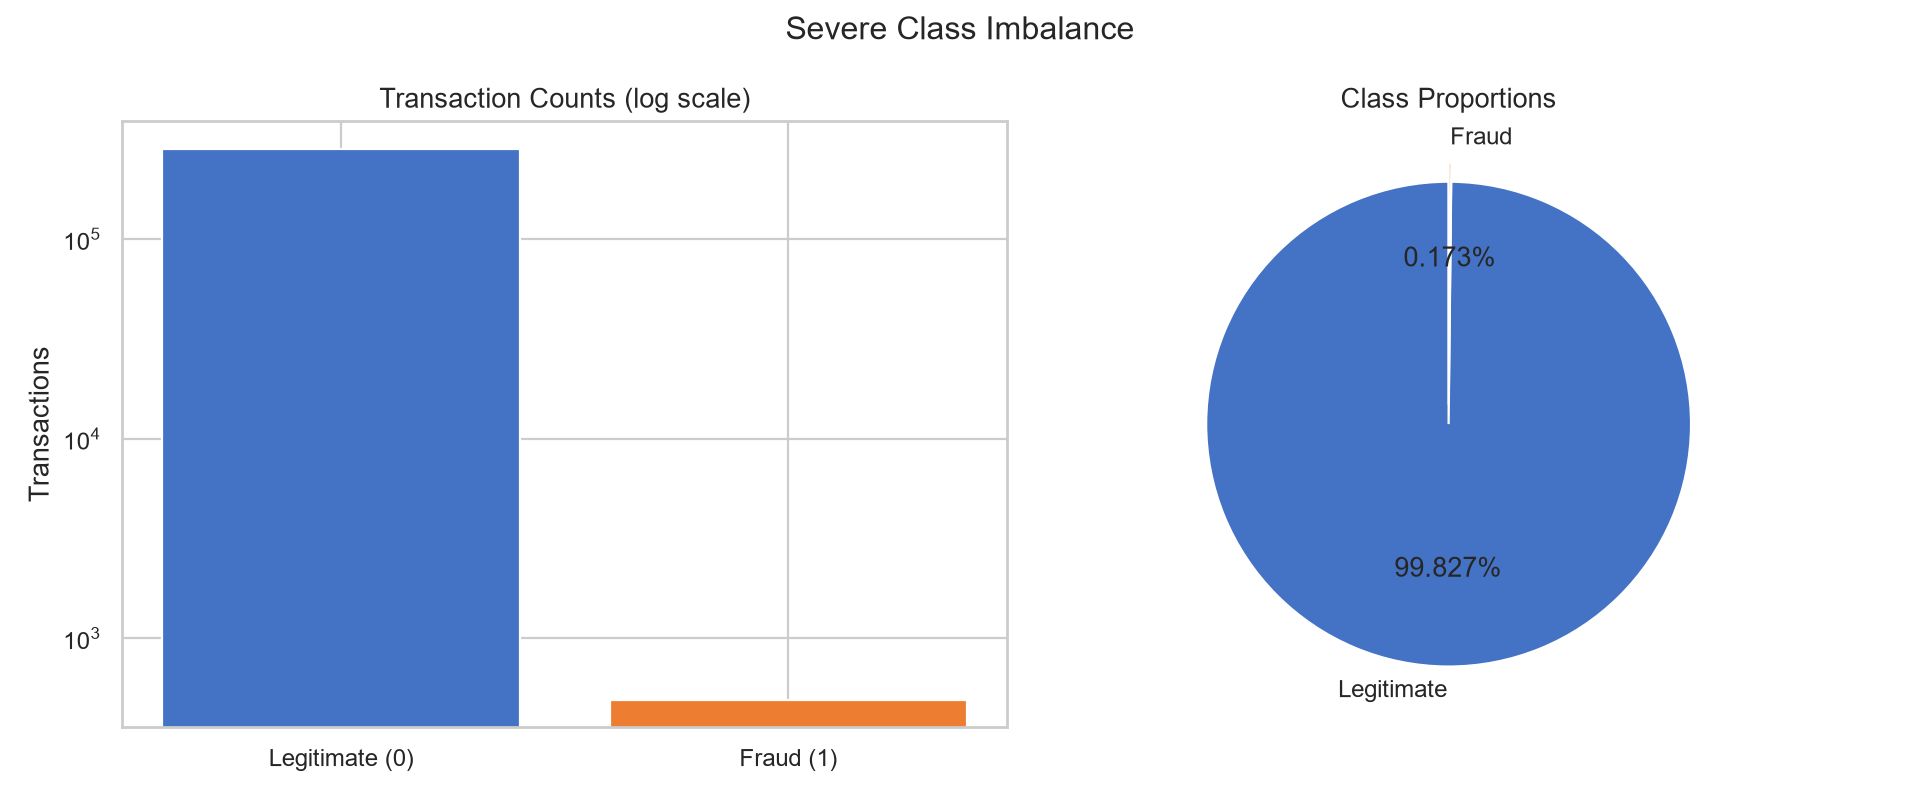

In [4]:
display(Image(filename=str(VISUALIZATION_DIR / 'class_distribution.png')))

## 5. Exploratory data analysis

### A. Transaction amount analysis

In [5]:
print("Amount statistics:")
display(data["Amount"].describe().to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, name, color in [(0, "Legitimate", "#4472C4"), (1, "Fraud", "#ED7D31")]:
    amounts = data.loc[data[TARGET_COLUMN] == label, "Amount"]
    axes[0].hist(np.log1p(amounts), bins=60, alpha=0.65, density=True, label=name, color=color)
    axes[1].boxplot(np.log1p(amounts), positions=[label + 1], widths=0.55, patch_artist=True,
                    boxprops={"facecolor": color, "alpha": 0.7}, medianprops={"color": "black"})
axes[0].set(title="Amount Distribution (log1p scale)", xlabel="log(1 + Amount)", ylabel="Density")
axes[0].legend()
axes[1].set(title="Amount by Class (log1p scale)", ylabel="log(1 + Amount)", xticks=[1, 2],
            xticklabels=["Legitimate", "Fraud"])
fig.tight_layout()
fig.savefig(VISUALIZATION_DIR / "transaction_amount_distribution.png", dpi=160)
plt.show()

Amount statistics:


,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000


C:\Users\HP\AppData\Local\Temp\ipykernel_26760\2890275480.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


The histograms and boxplots compare transaction amounts by class using log(1 + amount), which keeps large values from compressing the rest of the plot. The data-derived summary and chart reveal how much the distributions overlap; amount alone is not sufficient to classify a transaction.

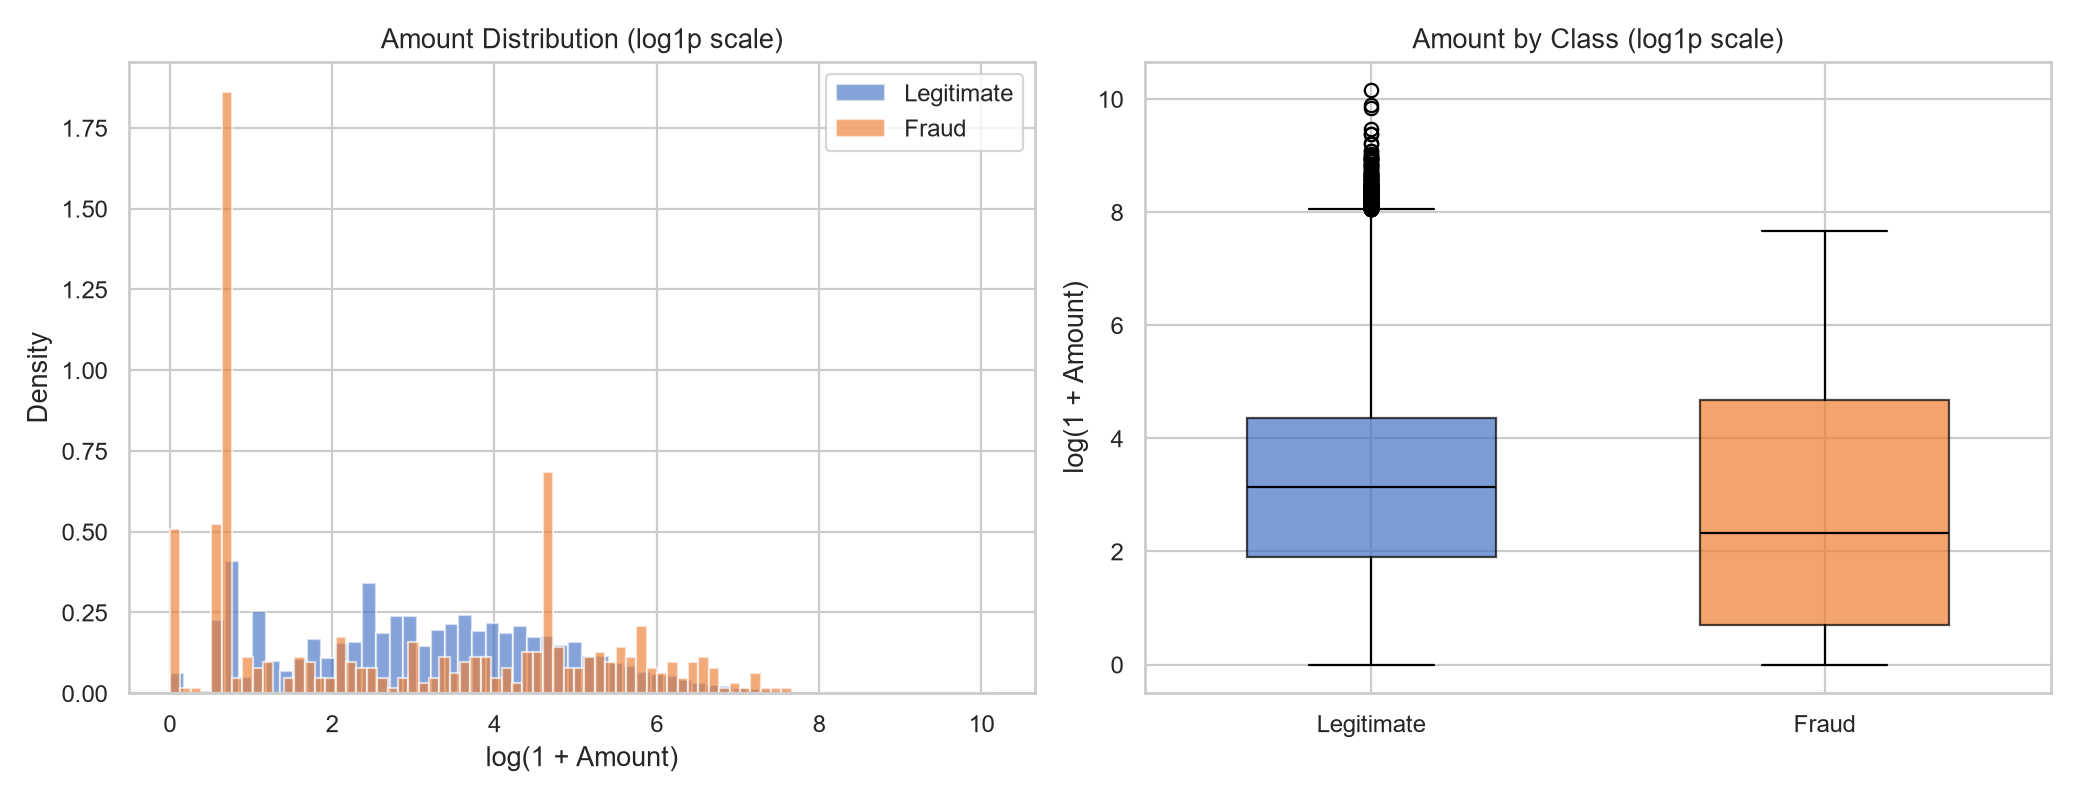

In [6]:
display(Image(filename=str(VISUALIZATION_DIR / 'transaction_amount_distribution.png')))

### B. Transaction time analysis

In [7]:
# Time is elapsed seconds, shown here as elapsed hours from the first record.
elapsed_hours = data["Time"] / 3600
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for label, name, color in [(0, "Legitimate", "#4472C4"), (1, "Fraud", "#ED7D31")]:
    axes[0].hist(elapsed_hours[data[TARGET_COLUMN] == label], bins=48, alpha=0.6,
                 label=name, color=color)
axes[0].set(title="Transactions by Elapsed Hour", ylabel="Transaction count")
axes[0].legend()
time_bins = np.linspace(elapsed_hours.min(), elapsed_hours.max(), 49)
bin_ids = np.digitize(elapsed_hours, time_bins[1:-1])
time_summary = pd.DataFrame({"bin": bin_ids, "fraud": data[TARGET_COLUMN].to_numpy()}).groupby("bin")["fraud"].agg(["mean", "count"])
time_summary = time_summary[time_summary["count"] >= 20]
time_centers = (time_bins[:-1] + time_bins[1:]) / 2
axes[1].plot(time_centers[time_summary.index], time_summary["mean"] * 100, marker="o", color="#ED7D31")
axes[1].set(title="Fraud Share by Elapsed-Time Bin (bins with at least 20 records)",
            xlabel="Elapsed hours from first recorded transaction", ylabel="Fraud share (%)")
fig.tight_layout()
fig.savefig(VISUALIZATION_DIR / "transaction_time_analysis.png", dpi=160)
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_26760\1653995118.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


The first panel counts transactions by elapsed hour; the second plots the fraud share in bins with at least 20 records to avoid highlighting tiny groups. `Time` spans elapsed seconds in this dataset, not wall-clock time, so this cannot establish hour-of-day behavior or a true seasonal pattern.

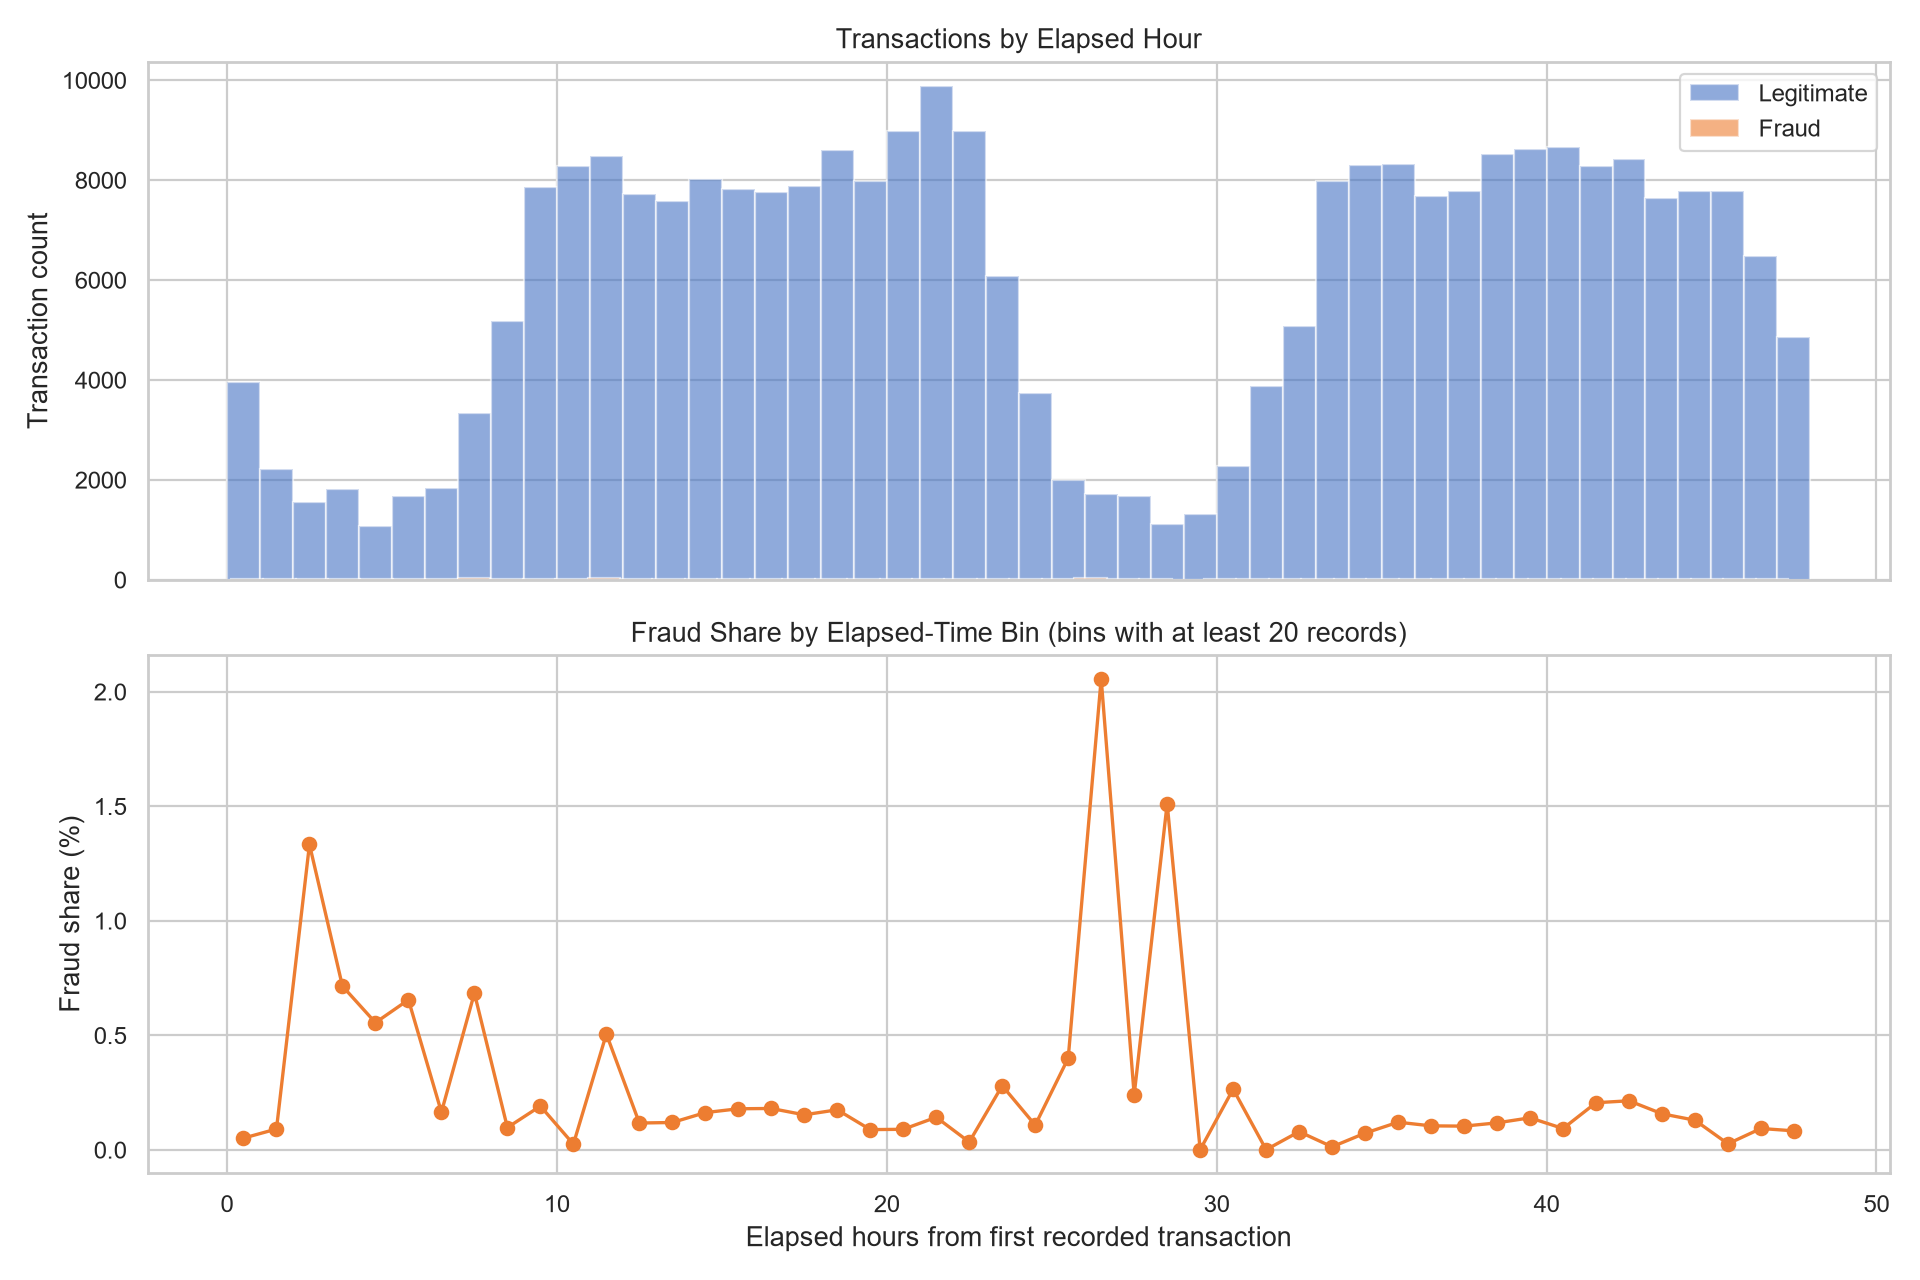

In [8]:
display(Image(filename=str(VISUALIZATION_DIR / 'transaction_time_analysis.png')))

### C. Correlation analysis

In [9]:
correlations = data.corr(numeric_only=True)
target_correlations = correlations[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(key=lambda values: values.abs(), ascending=False)
print("Features with largest absolute correlation to Class:")
display(target_correlations.head(10).to_frame("Correlation with Class"))
fig, axis = plt.subplots(figsize=(16, 13))
sns.heatmap(correlations, cmap="coolwarm", center=0, ax=axis, xticklabels=True, yticklabels=True,
            cbar_kws={"shrink": 0.75})
axis.set_title("Feature Correlation Heatmap")
fig.tight_layout()
fig.savefig(VISUALIZATION_DIR / "correlation_heatmap.png", dpi=160)
plt.show()

Features with largest absolute correlation to Class:


,Correlation with Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V11,0.154876
V4,0.133447
V18,-0.111485


C:\Users\HP\AppData\Local\Temp\ipykernel_26760\1141982409.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


The heatmap shows pairwise linear correlations, and the table ranks each feature's linear association with the target. Correlation can help describe the benchmark, but it does not prove causation and does not capture every nonlinear relationship used by the classifiers.

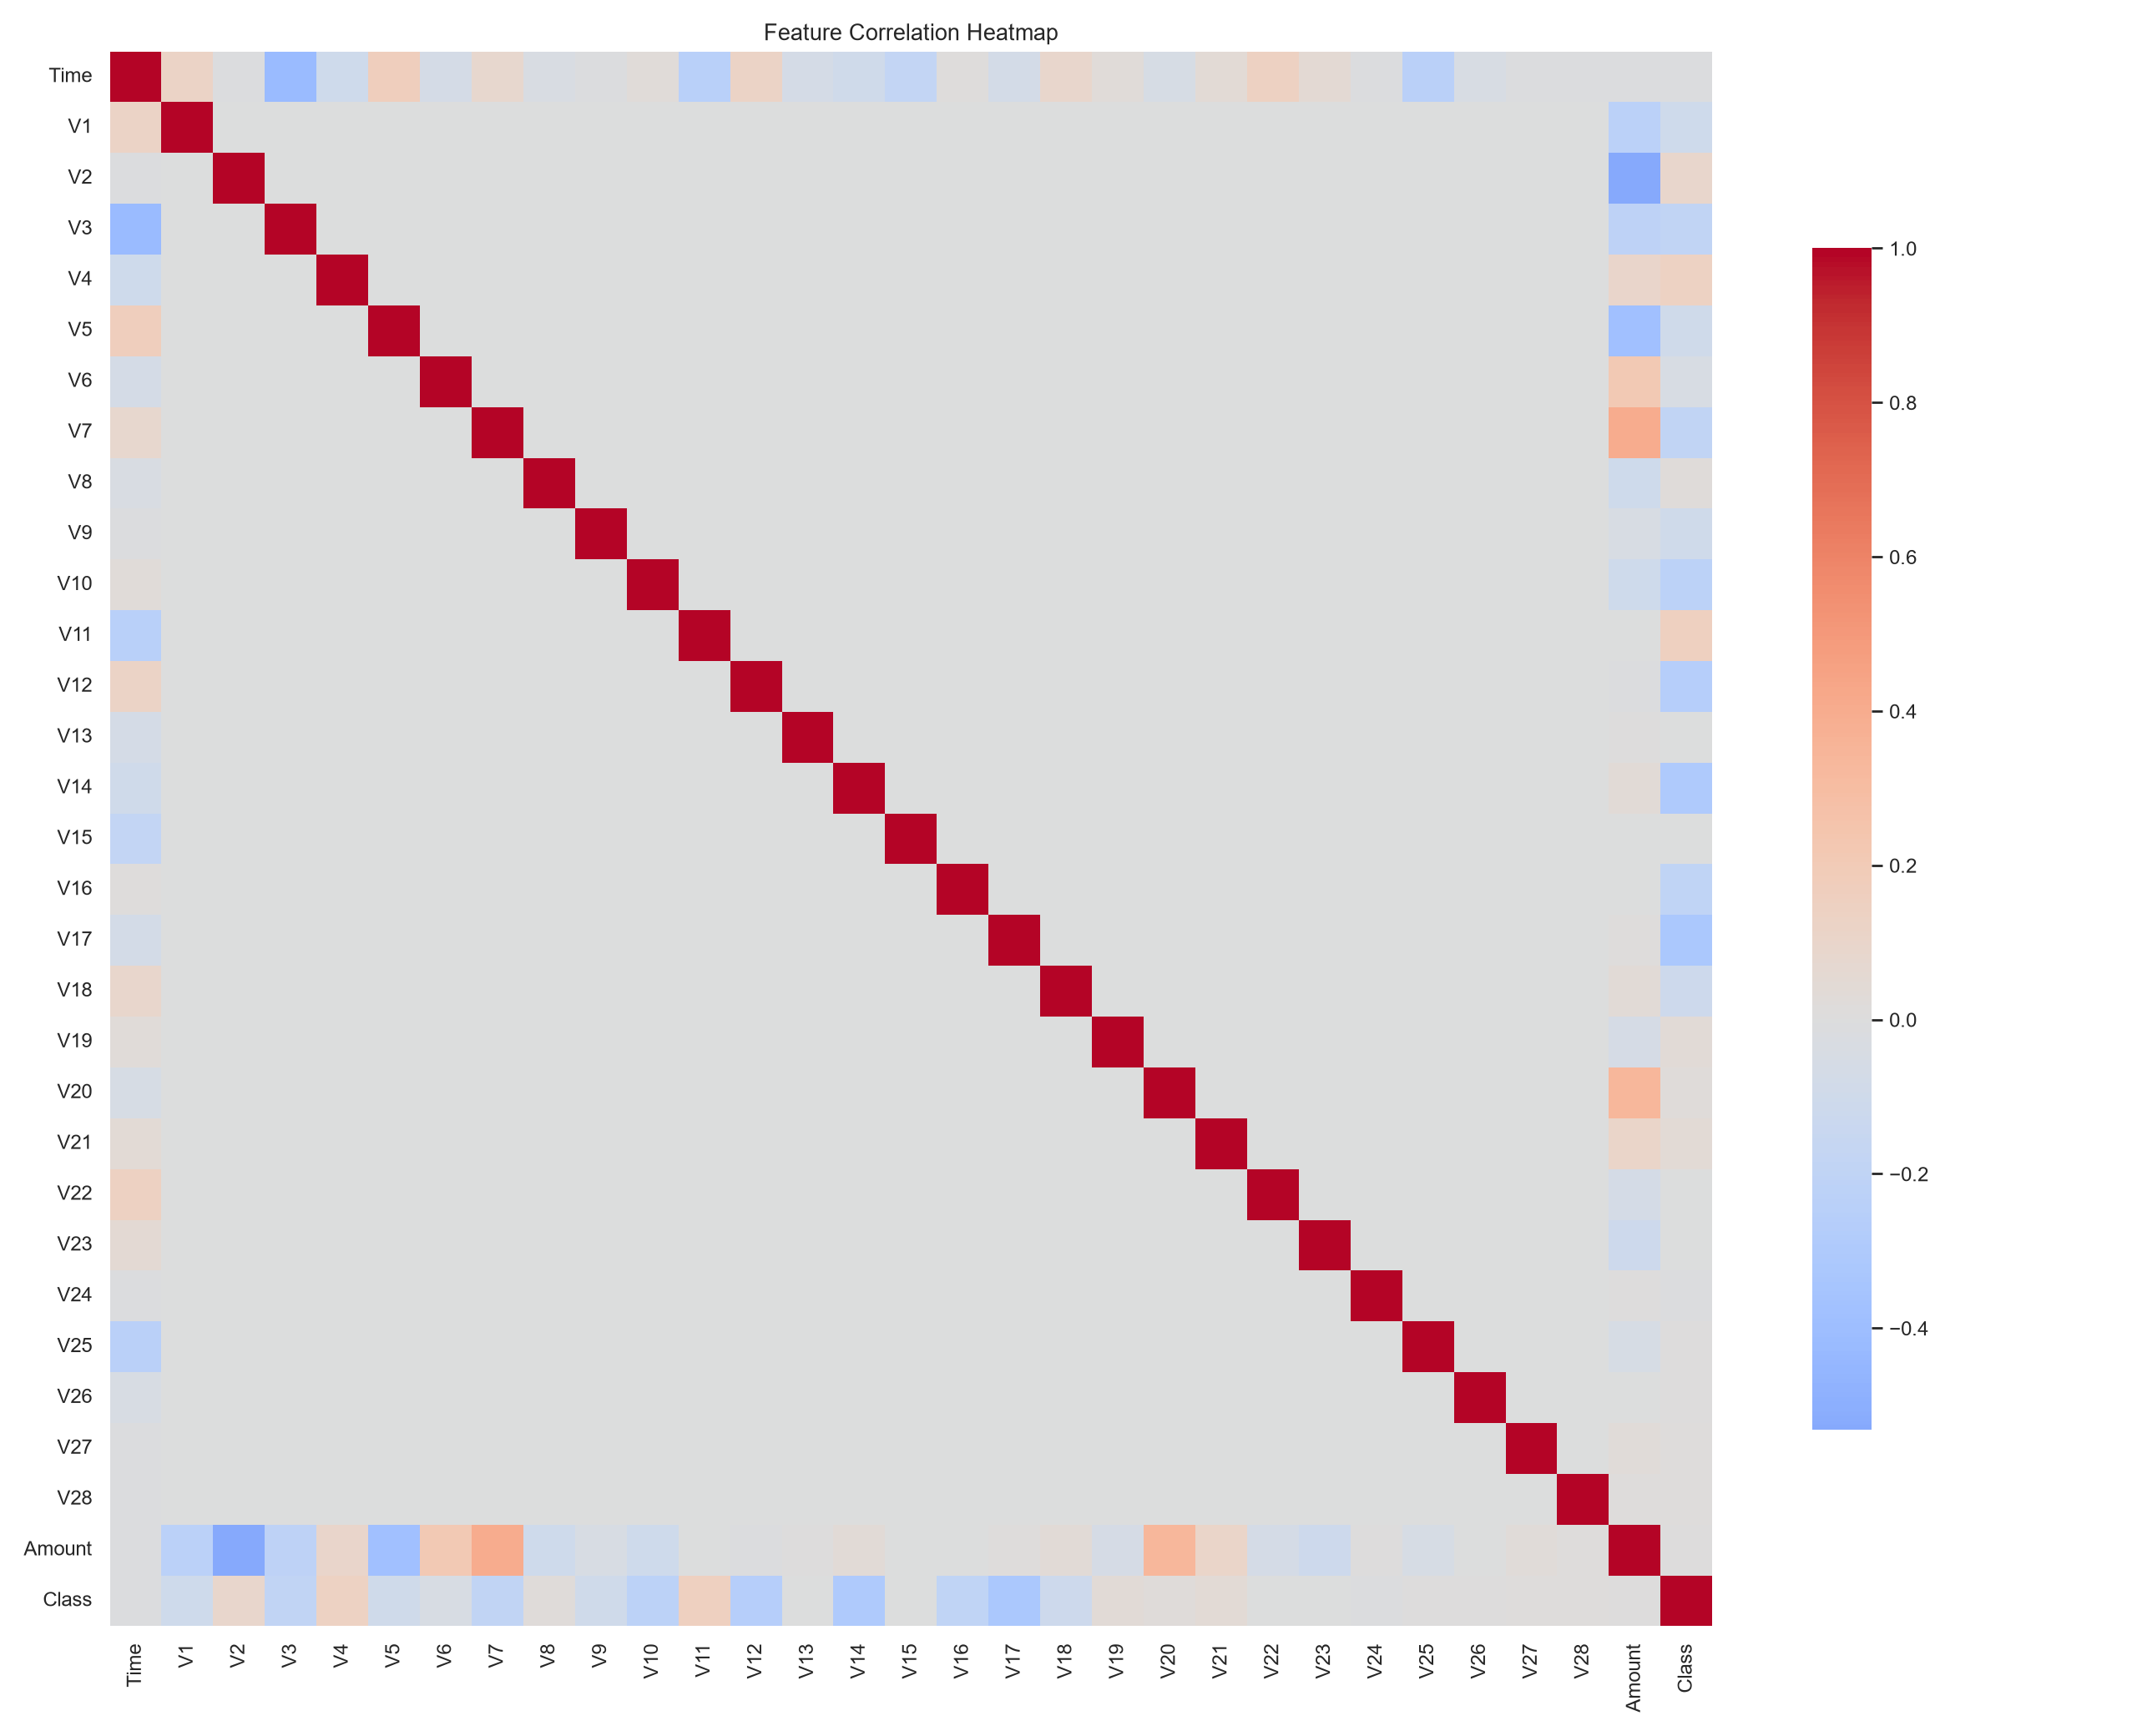

In [10]:
display(Image(filename=str(VISUALIZATION_DIR / 'correlation_heatmap.png')))

## 6. Data preprocessing

Missing values and exact duplicate records are measured before modeling. The dataset contains 1,081 exact duplicate records; these exact repeats are removed before the train-test split to prevent information leakage. The complete raw CSV is preserved. The source has numeric features, including transformed `V1`?`V28`. `Class` is separated from predictors. A `StandardScaler` is fitted inside each training pipeline, so its statistics never use the test set. No source feature is dropped and no label-derived feature is created.

In [11]:
missing_cells = int(data.isna().sum().sum())
duplicate_rows = int(data.duplicated().sum())
invalid_amounts = int((data["Amount"] < 0).sum())
invalid_times = int((data["Time"] < 0).sum())
X = data.drop(columns=[TARGET_COLUMN])
y = data[TARGET_COLUMN].astype("int8")
assert TARGET_COLUMN not in X.columns
assert missing_cells == 0, "Unexpected missing data needs explicit handling before training."
assert invalid_amounts == 0 and invalid_times == 0, "Unexpected negative amount/time values need review."
print("Missing cells:", missing_cells)
print("Exact duplicate rows removed before modeling:", duplicate_rows)
print("Negative Amount rows:", invalid_amounts)
print("Negative Time rows:", invalid_times)
print("Features:", X.shape[1], "Target classes:", sorted(y.unique().tolist()))

Missing cells: 0
Exact duplicate rows removed before modeling: 1081
Negative Amount rows: 0
Negative Time rows: 0
Features: 30 Target classes: [0, 1]


## 7. Stratified train-test split

An 80/20 split is performed before oversampling. Stratification preserves approximately the same rare fraud proportion in both partitions, making the holdout evaluation more representative. `random_state=42` makes the split reproducible.

In [12]:
x_train, x_test, y_train, y_test = split_features_target(data)
assert len(x_train) + len(x_test) == len(data) - duplicate_rows
assert set(y_train.unique()) == {0, 1} and set(y_test.unique()) == {0, 1}
train_test_counts = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1]),
    "Testing": y_test.value_counts().reindex([0, 1]),
})
print("Training feature shape:", x_train.shape)
print("Testing feature shape:", x_test.shape)
print("Training fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))
display(train_test_counts)

Training feature shape: (226980, 30)
Testing feature shape: (56746, 30)
Training fraud cases: 378
Testing fraud cases: 95


,Training,Testing
Class,,
0,226602,56651
1,378,95


## 8. Handle class imbalance using SMOTE

SMOTE (Synthetic Minority Over-sampling Technique) creates new minority-class training examples by interpolating between nearby minority examples. It helps the learner see more fraud-like examples, but does not add real observed fraud. It is applied only after the split and only inside the training pipelines. The test set remains untouched and keeps its original rare-class distribution.

In [13]:
from imblearn.over_sampling import SMOTE

training_counts_before = y_train.value_counts().reindex([0, 1], fill_value=0)
smote_demo = SMOTE(random_state=42)
x_train_resampled_demo, y_train_resampled_demo = smote_demo.fit_resample(x_train, y_train)
training_counts_after = y_train_resampled_demo.value_counts().reindex([0, 1], fill_value=0)
smote_count_table = pd.DataFrame({"Before SMOTE": training_counts_before, "After SMOTE": training_counts_after})
smote_count_table.index = ["Legitimate (0)", "Fraud (1)"]
display(smote_count_table)
print("Untouched test class counts:")
print(y_test.value_counts().sort_index())
assert y_test.equals(data.loc[y_test.index, TARGET_COLUMN].astype("int8")), "Test labels differ from the original dataset rows."
fig, axis = plt.subplots(figsize=(8, 5))
smote_count_table.plot(kind="bar", ax=axis, color=["#4472C4", "#70AD47"])
axis.set(title="Training Class Counts Before and After SMOTE", ylabel="Transactions", xlabel="Class")
axis.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(VISUALIZATION_DIR / "smote_class_distribution.png", dpi=160)
plt.show()
del x_train_resampled_demo, y_train_resampled_demo, smote_demo
gc.collect()

,Before SMOTE,After SMOTE
Legitimate (0),226602,226602
Fraud (1),378,226602


Untouched test class counts:
Class
0    56651
1       95
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_26760\3659768285.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


56

The training-only fraud count is brought up to the training majority count by SMOTE. The comparison chart describes training data only; the original imbalanced test data remains unchanged for fair evaluation.

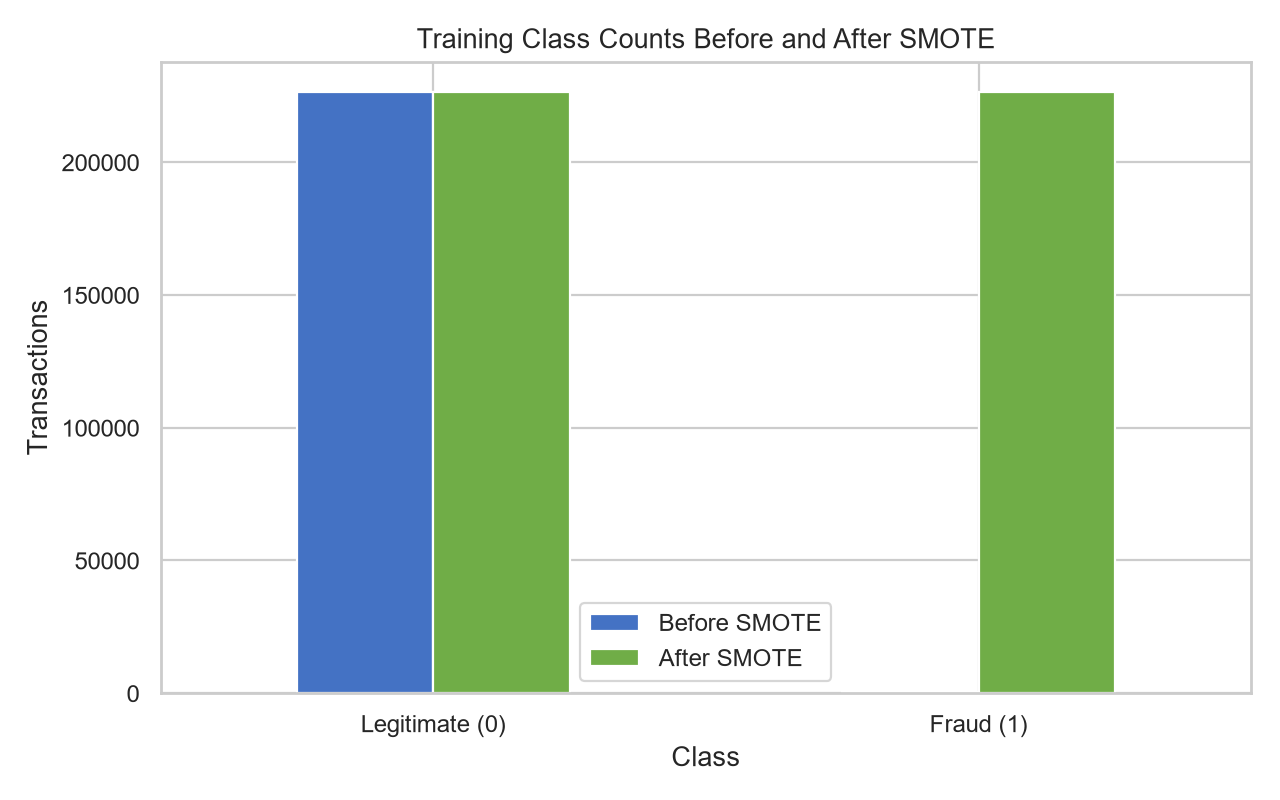

In [14]:
display(Image(filename=str(VISUALIZATION_DIR / 'smote_class_distribution.png')))

## 9. Train machine-learning models

**Logistic Regression** is a baseline that estimates class probabilities from a weighted combination of numeric features. **Random Forest** combines many decision trees; their votes can capture nonlinear interactions. Each saved imbalanced-learn pipeline contains a training-fitted scaler, SMOTE, and estimator. During prediction, the fitted pipeline scales test rows but does not resample them.

In [15]:
models, pipeline_smote_counts = train_models(x_train, y_train)
display(pipeline_smote_counts.set_index("Class").rename(index={0: "Legitimate", 1: "Fraud"}))
print("Both models trained on the same training split and saved to:", MODEL_DIR)

Training Logistic Regression...


Saved Logistic Regression pipeline to C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\models\logistic_regression_model.joblib
Training Random Forest...


Saved Random Forest pipeline to C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\models\random_forest_model.joblib


,Before SMOTE,After SMOTE
Class,,
Legitimate,226602,226602
Fraud,378,226602


Both models trained on the same training split and saved to: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\models


## 10. Model evaluation

Both models predict on the same original, stratified, imbalanced test set. The confusion matrix counts true negatives (legitimate correctly identified), false positives (legitimate incorrectly flagged), false negatives (fraud missed), and true positives (fraud correctly detected).

In [16]:
comparison, predictions, probabilities = evaluate_models(models, x_test, y_test)
display(comparison)
print((REPORT_DIR / "classification_reports.txt").read_text(encoding="utf-8"))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.973672,0.053035,0.873684,0.100000,0.962618
Random Forest,0.999277,0.793478,0.768421,0.780749,0.975715


=== Logistic Regression ===
                precision    recall  f1-score   support

Legitimate (0)     0.9998    0.9738    0.9866     56651
     Fraud (1)     0.0530    0.8737    0.1000        95

      accuracy                         0.9737     56746
     macro avg     0.5264    0.9238    0.5433     56746
  weighted avg     0.9982    0.9737    0.9852     56746

=== Random Forest ===
                precision    recall  f1-score   support

Legitimate (0)     0.9996    0.9997    0.9996     56651
     Fraud (1)     0.7935    0.7684    0.7807        95

      accuracy                         0.9993     56746
     macro avg     0.8965    0.8840    0.8902     56746
  weighted avg     0.9993    0.9993    0.9993     56746



Accuracy is the share of all predictions that are correct; precision is the share of flagged transactions that are fraud; recall is the share of fraud cases detected; F1 balances precision and recall; ROC-AUC summarizes ranking quality across thresholds. With rare fraud, Precision?Recall curves show the precision/recall trade-off more directly than accuracy. Curves and confusion matrices below use only the held-out test data.

The matrix shows correct and incorrect Logistic Regression decisions. False negatives represent missed fraud; false positives are legitimate transactions flagged for review.

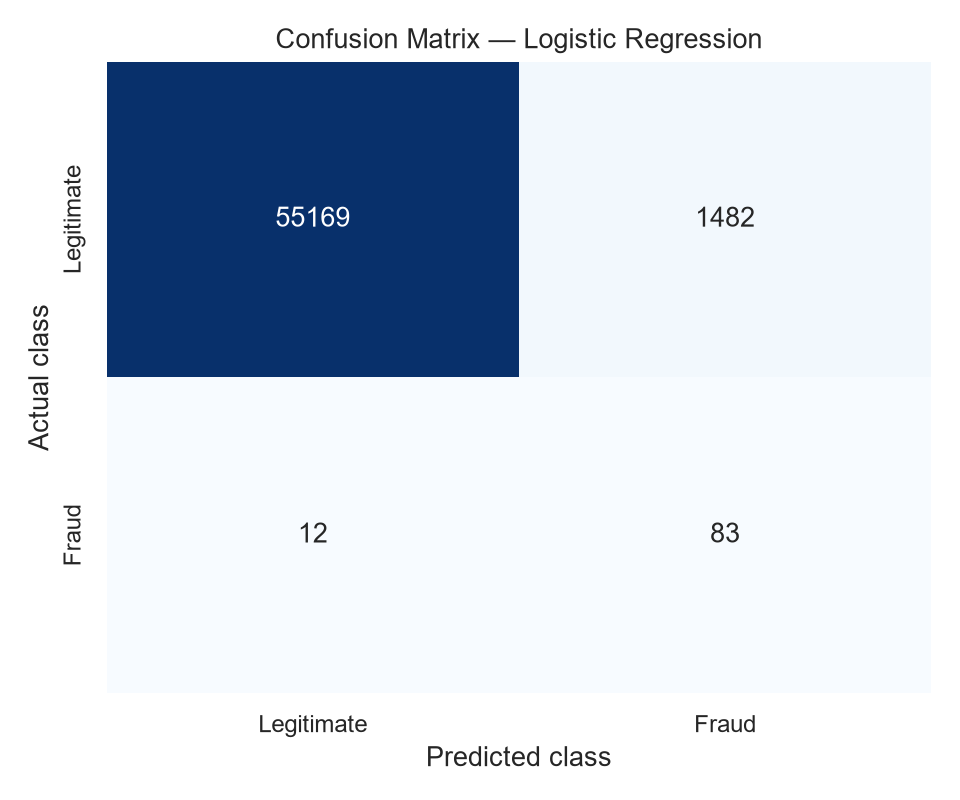

In [17]:
display(Image(filename=str(VISUALIZATION_DIR / 'confusion_matrix_logistic.png')))

The matrix shows correct and incorrect Random Forest decisions. Compare false negatives and false positives with business costs, not just the total accuracy.

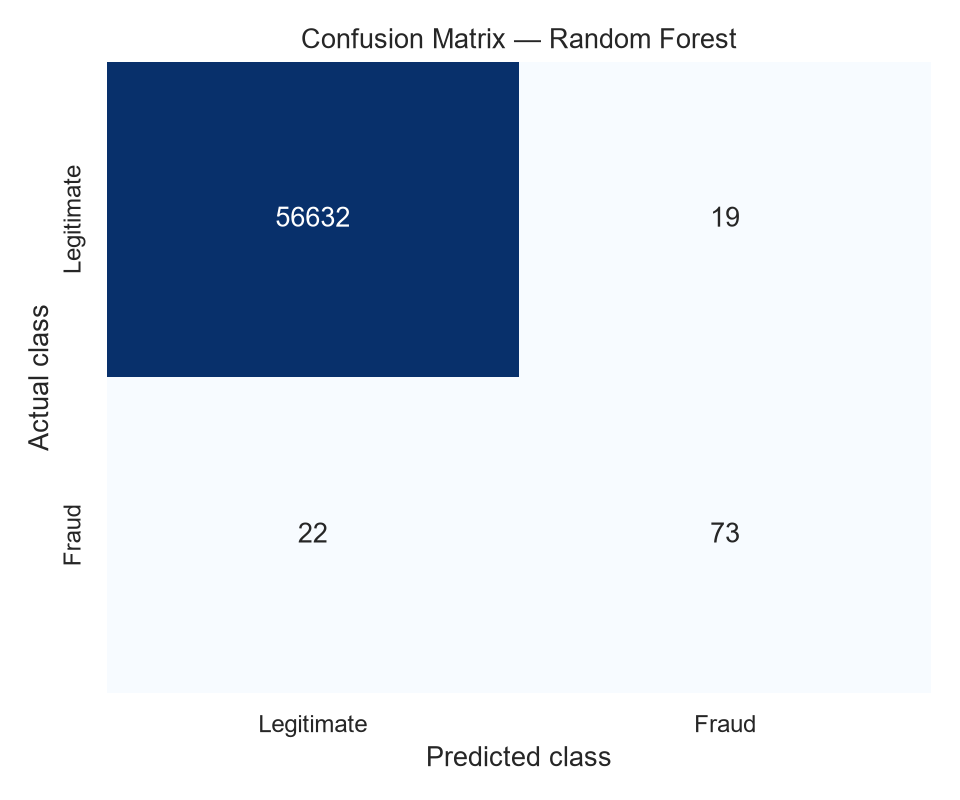

In [18]:
display(Image(filename=str(VISUALIZATION_DIR / 'confusion_matrix_random_forest.png')))

The ROC curves compare true-positive and false-positive rates over decision thresholds; the diagonal is random ranking. ROC-AUC is useful, but rare-class precision still needs separate review.

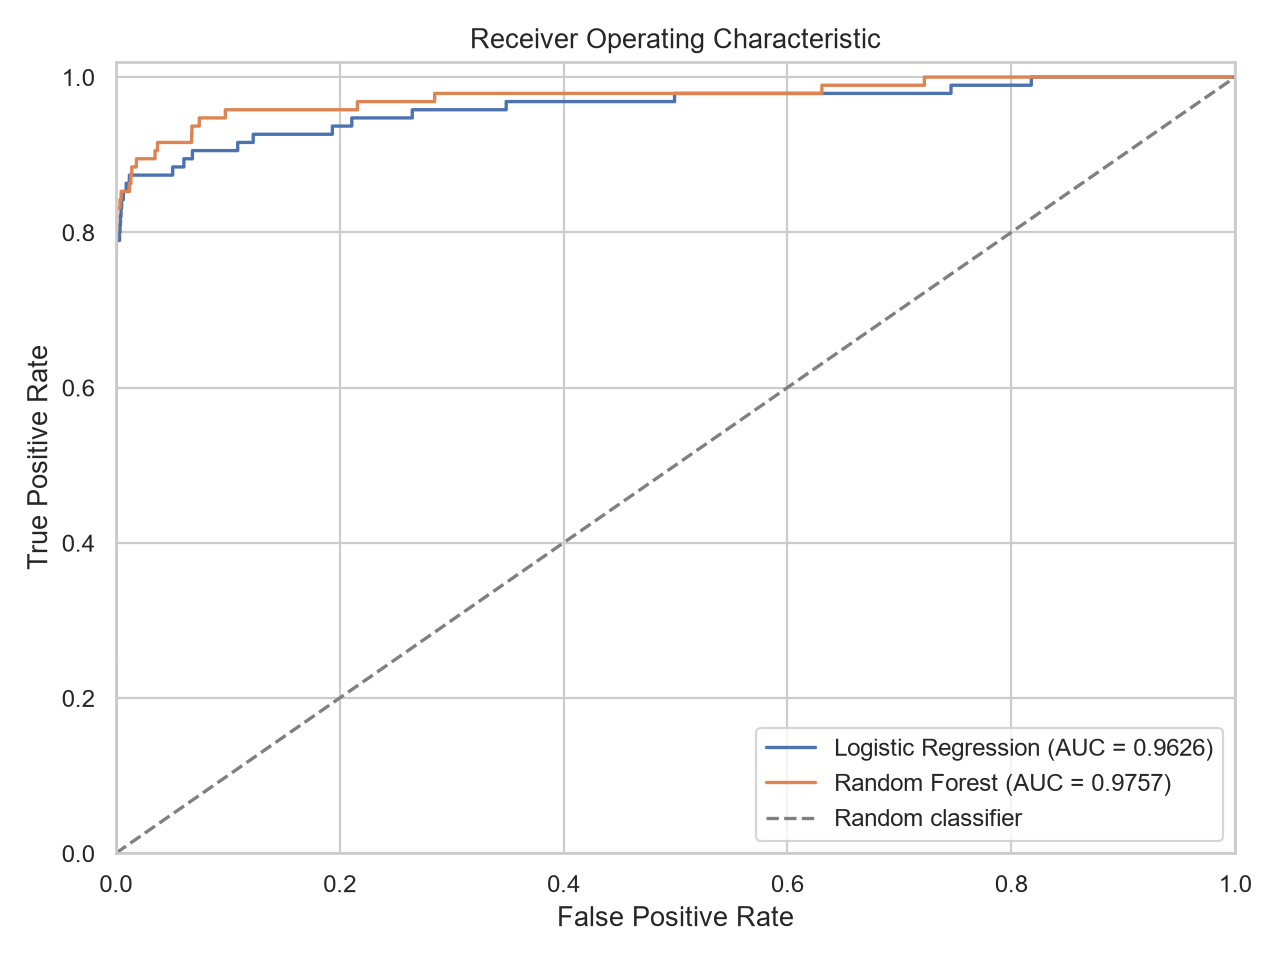

In [19]:
display(Image(filename=str(VISUALIZATION_DIR / 'roc_curve.png')))

The Precision?Recall curves show how detecting more fraud can increase false alerts. The prevalence reference line highlights why precision is difficult when fraud is rare.

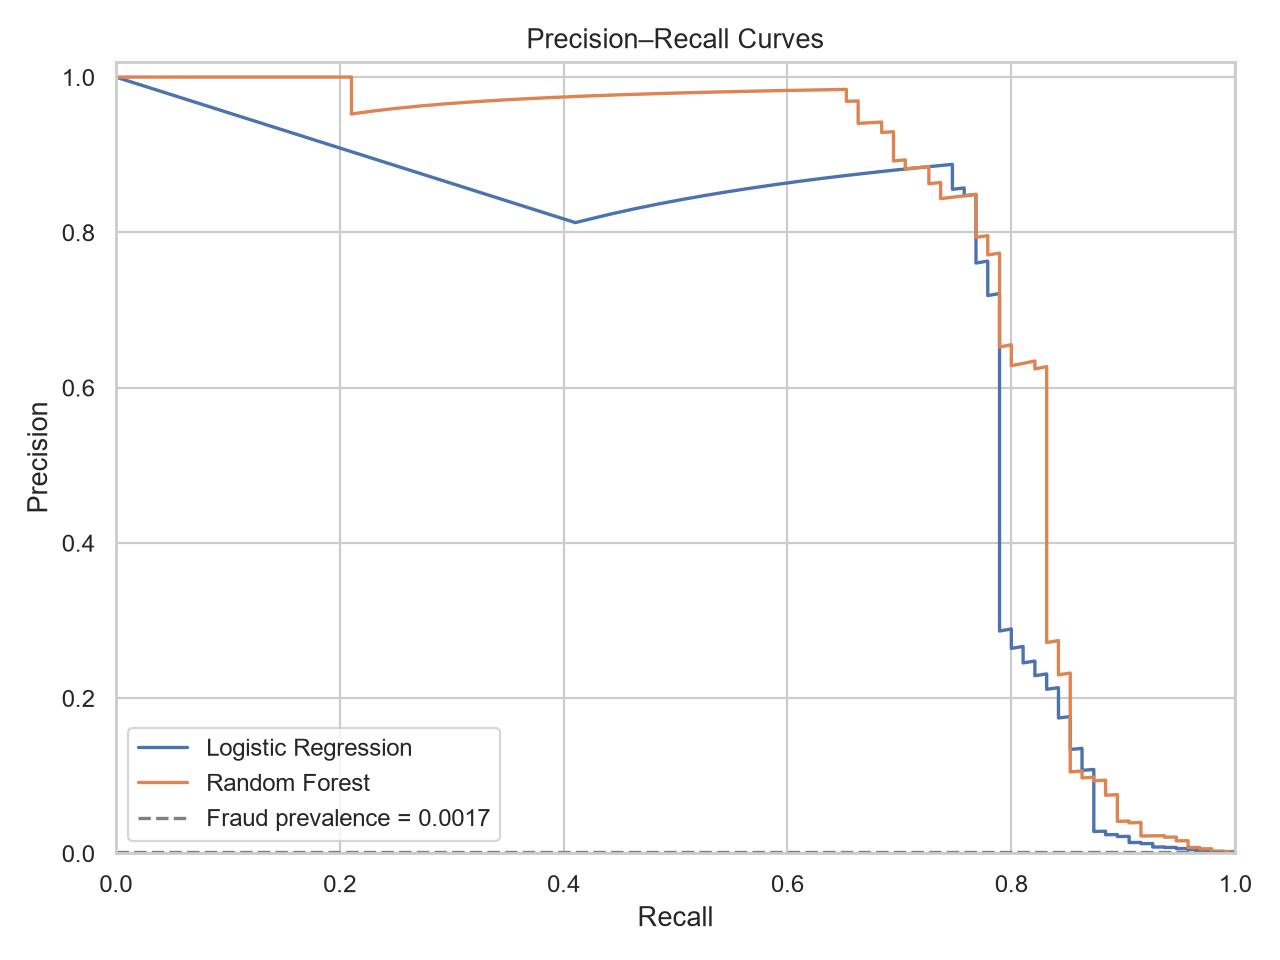

In [20]:
display(Image(filename=str(VISUALIZATION_DIR / 'precision_recall_curve.png')))

### Actual model comparison

In [21]:
print("Model comparison saved to:", REPORT_DIR / "model_comparison.csv")
print("Classification reports saved to:", REPORT_DIR / "classification_reports.txt")

Model comparison saved to: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\reports\model_comparison.csv
Classification reports saved to: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\reports\classification_reports.txt


## 11. Which metric matters most?

For screening, we prioritize **recall** so fewer fraudulent transactions are missed, while reviewing **precision** because false alerts can interrupt legitimate customers and consume investigator time. F1-score summarizes this trade-off, and ROC-AUC provides a threshold-independent ranking view. Accuracy alone is inadequate for a highly imbalanced target. The models use the default 0.5 probability threshold; no threshold is tuned on the test data. A production threshold should be chosen using a separate validation period and explicit loss/capacity costs.

In [22]:
# Select by recall first, then precision and F1, using the displayed holdout comparison.
ranked_models = comparison.sort_values(
    ["Recall", "Precision", "F1-score"], ascending=False
)
best_model_name = ranked_models.index[0]
print("Recall-first model for the error analysis:", best_model_name)
display(ranked_models)

Recall-first model for the error analysis: Logistic Regression


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.973672,0.053035,0.873684,0.100000,0.962618
Random Forest,0.999277,0.793478,0.768421,0.780749,0.975715


## 12. Feature importance analysis

Random Forest impurity-based importance measures how much a feature contributed to reducing split impurity across the fitted trees. It is predictive contribution, not causation; correlated anonymized variables can share or distort importance.

In [23]:
feature_importance = save_feature_importance(models["Random Forest"], x_train.columns)
display(feature_importance.head(10))

,Feature,Importance
14,V14,0.200546
10,V10,0.124713
12,V12,0.098334
17,V17,0.091141
4,V4,0.086885
11,V11,0.056680
3,V3,0.056647
16,V16,0.055760
2,V2,0.038591
9,V9,0.025680


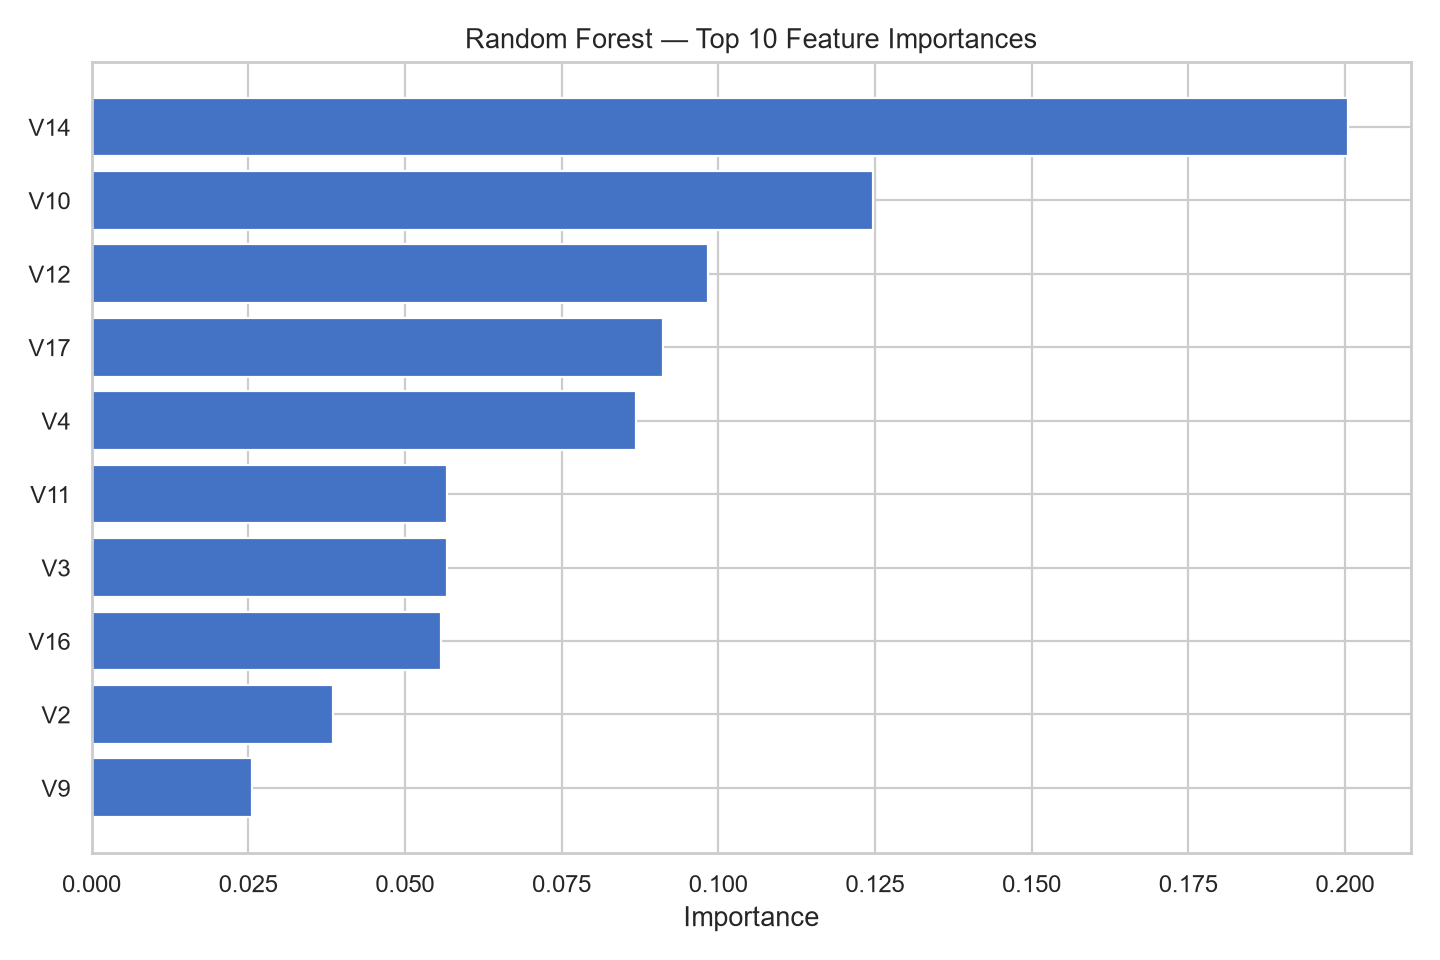

In [24]:
display(Image(filename=str(VISUALIZATION_DIR / 'feature_importance.png')))

The table and chart rank the ten largest calculated importances for this fitted Random Forest. `V1`?`V28` are anonymized, so their substantive meaning cannot be inferred from rank alone.

## 13. Error analysis

The next table shows at most ten examples from the recall-first model: up to five false positives and five false negatives. It includes only a test-row position, actual and predicted labels, and fraud probability?not the full feature vector. False alarms may share patterns with fraud; missed fraud may resemble legitimate cases or receive a probability below the default threshold.

In [25]:
error_examples = save_error_analysis(
    x_test, y_test, predictions, probabilities, model_name=best_model_name
)
display(error_examples)
print("Error examples saved to:", REPORT_DIR / "misclassified_examples.csv")

,Model,Test_Row_Position,Error_Type,Actual_Class,Predicted_Class,Predicted_Fraud_Probability
0,Logistic Regression,16,False Positive,0,1,0.551360
1,Logistic Regression,145,False Positive,0,1,0.911538
2,Logistic Regression,155,False Positive,0,1,0.523027
3,Logistic Regression,156,False Positive,0,1,0.935908
4,Logistic Regression,157,False Positive,0,1,0.507317
5,Logistic Regression,4480,False Negative,1,0,0.085602
6,Logistic Regression,5187,False Negative,1,0,0.024377
7,Logistic Regression,22495,False Negative,1,0,0.319189
8,Logistic Regression,27361,False Negative,1,0,0.258089
9,Logistic Regression,29007,False Negative,1,0,0.005267


Error examples saved to: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\reports\misclassified_examples.csv


## 14. Scalability discussion

One million transactions per hour is approximately 277.8 transactions per second. A production architecture could ingest transactions with Apache Kafka, calculate low-latency features in a streaming service, call a horizontally scaled FastAPI scoring service, use Redis for carefully selected low-latency cached features, persist scores and alerts to a database, and monitor latency, drift, precision, and recall for retraining. Capacity would require load testing, resilience design, security/privacy controls, and operational monitoring. This notebook does not implement these services and is not connected to a bank or payment gateway.

## 15. Final results and key findings

In [26]:
fraud_row = class_report.loc[class_report["Class"] == 1].iloc[0]
best_metrics = comparison.loc[best_model_name]
print(f"Dataset: {len(data):,} rows, {len(feature_columns)} features")
print(f"Legitimate transactions: {int(class_report.loc[class_report['Class'] == 0, 'Transaction_Count'].iloc[0]):,}")
print(f"Fraudulent transactions: {int(fraud_row['Transaction_Count']):,} ({fraud_row['Percentage']:.6f}%)")
print(f"Unique modeling records: {len(x_train) + len(x_test):,}; training before SMOTE: {len(x_train):,}; after SMOTE: {int(training_counts_after.sum()):,}")
print(f"Untouched test records: {len(x_test):,}; fraud cases: {int(y_test.sum()):,}")
print("Actual model comparison:")
display(comparison)
print(f"Recall-first choice: {best_model_name}; recall={best_metrics['Recall']:.4f}, precision={best_metrics['Precision']:.4f}, F1={best_metrics['F1-score']:.4f}, ROC-AUC={best_metrics['ROC-AUC']:.4f}")
print("Data-driven observations:")
print(f"1. Fraud prevalence is {fraud_row['Percentage']:.6f}% in the full benchmark.")
print(f"2. Stratification preserved fraud in both partitions: {int(y_train.sum()):,} training and {int(y_test.sum()):,} testing cases before SMOTE.")
print(f"3. SMOTE changed only training size from {len(y_train):,} to {int(training_counts_after.sum()):,}; test size stayed {len(y_test):,}.")
print(f"4. Logistic Regression holdout recall/precision: {comparison.loc['Logistic Regression','Recall']:.4f}/{comparison.loc['Logistic Regression','Precision']:.4f}.")
print(f"5. Random Forest holdout recall/precision: {comparison.loc['Random Forest','Recall']:.4f}/{comparison.loc['Random Forest','Precision']:.4f}.")
print(f"6. The raw benchmark has {duplicate_rows:,} exact duplicate rows and {missing_cells:,} missing cells; exact repeats were removed before splitting to prevent leakage.")

Dataset: 284,807 rows, 30 features
Legitimate transactions: 284,315
Fraudulent transactions: 492 (0.172749%)
Unique modeling records: 283,726; training before SMOTE: 226,980; after SMOTE: 453,204
Untouched test records: 56,746; fraud cases: 95
Actual model comparison:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.973672,0.053035,0.873684,0.100000,0.962618
Random Forest,0.999277,0.793478,0.768421,0.780749,0.975715


Recall-first choice: Logistic Regression; recall=0.8737, precision=0.0530, F1=0.1000, ROC-AUC=0.9626
Data-driven observations:
1. Fraud prevalence is 0.172749% in the full benchmark.
2. Stratification preserved fraud in both partitions: 378 training and 95 testing cases before SMOTE.
3. SMOTE changed only training size from 226,980 to 453,204; test size stayed 56,746.
4. Logistic Regression holdout recall/precision: 0.8737/0.0530.
5. Random Forest holdout recall/precision: 0.7684/0.7935.
6. The raw benchmark has 1,081 exact duplicate rows and 0 missing cells; exact repeats were removed before splitting to prevent leakage.


## 16. Conclusion

This project compared Logistic Regression and Random Forest on the public fraud benchmark, used stratified splitting to preserve rare-class representation, and placed scaling and SMOTE inside training-only pipelines. Precision, recall, F1, ROC-AUC, class reports, and confusion matrices give more useful views than accuracy alone. The final model choice and all numeric findings above come from this executed holdout evaluation. Historical anonymized data, dataset shift, threshold costs, and the absence of production testing limit real-world conclusions.

## 17. Save and reuse the trained models

In [27]:
logistic_path = MODEL_DIR / "logistic_regression_model.joblib"
forest_path = MODEL_DIR / "random_forest_model.joblib"
loaded_forest = joblib.load(forest_path)
sample_transaction = x_test.iloc[[0]]
sample_prediction = int(loaded_forest.predict(sample_transaction)[0])
sample_probability = float(loaded_forest.predict_proba(sample_transaction)[0, 1])
print("Loaded saved pipeline:", forest_path)
print("One correctly formatted test row:", sample_transaction.shape)
print("Predicted class:", sample_prediction, "(1 = fraud, 0 = legitimate)")
print(f"Predicted fraud probability: {sample_probability:.6f}")
print("Saved pipelines include their fitted scaler; SMOTE is not applied during inference.")

Loaded saved pipeline: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-FraudDetection\models\random_forest_model.joblib
One correctly formatted test row: (1, 30)
Predicted class: 0 (1 = fraud, 0 = legitimate)
Predicted fraud probability: 0.007582
Saved pipelines include their fitted scaler; SMOTE is not applied during inference.


The joblib artifacts contain the fitted preprocessing and classifier pipeline. They are intended for learning and offline demonstration only, not for authorizing real payments.